# PTB-XL ECG forecasting: the experiment in one notebook

**Task.** Observe the first **7 s** of a 12-lead ECG (100 Hz, 700 samples) and forecast the
next **2.9 s** (290 samples) in raw mV.

This notebook walks through the study end to end, on a scale you can run in minutes:

| Step | What you do | Study phase |
|---|---|---|
| 1 | Load the cleaned data and look at one record | 1.5–3 |
| 2 | Build a leakage-free, patient-level split | 4, 8 |
| 3 | Make the two reference forecasts: **flat** and **`sn4`** (plus the **oracle**) | 0 |
| 4 | Score forecasts with MAE + 3 gatekeepers | 6 |
| 5 | Train a model of your choice (default: the final `sn4`-gated CNN-LSTM) | 9–11 |
| 6 | Load the study's own cached results (6-seed ensembles) | 9–10 |
| 7 | Compare all methods with the D6.2 rule | 6, 8 |
| 8 | Visualise forecasts, error over the horizon and the learned gate | 13–15 |
| 9 | Commands to rerun the **full** study (Phases 0–18) | all |

Everything is controlled by the **CONFIG** cell below. Defaults are small (a fraction of the
training data, a few epochs, a subset of the evaluation fold), so numbers from a quick run are
*illustrative*; the study's numbers come from step 6 or from the full pipeline in step 9.

**Before you start**
- Run from the repository with its environment: `uv sync --locked --extra cpu --group notebook`
  (add `--extra tracking` if you use MLflow: `uv sync` removes extras you do not list),
  then select the `.venv` kernel (VS Code) or run `uv run jupyter lab`.
- Data must be in `PTB-XL/` (`uv run python scripts/download_ptbxl.py --root PTB-XL`).
- The sealed test fold 10 is never loaded here.

Background: [`reports/STUDY_GUIDE.md`](../reports/STUDY_GUIDE.md) and
[`reports/FINAL_REPORT.md`](../reports/FINAL_REPORT.md).

## 0. Configuration
Change values here, then *Run All*. Nothing else needs editing.

In [1]:
CONFIG = dict(
    # --- evaluation -----------------------------------------------------------------
    eval_fold=9,            # official PTB-XL fold to evaluate on: 1..9 (fold 10 is sealed)
    n_eval_records=300,     # records of that fold to score; None = all (~2,000, slower)
    # --- training of your own model (step 5) -------------------------------------------
    train=True,             # False: skip training and only use baselines + cached study runs
    model="gated",          # gated    : final model, sigmoid(gate) * sn4 + correction
                            # additive : ablation, sn4 + correction (no gate)
                            # input    : ablation, sn4 only as extra input channels
                            # cnn_lstm : plain CNN-LSTM, L1 loss (Phase 9 winner on MAE)
                            # cnn | lstm | patchtst | transformer : other Phase 9 families
    train_fraction=0.10,    # share of training patients (study: 1.0)
    epochs=8,               # max epochs (study: 100, early stopping patience 5)
    patience=5,
    seeds=[42],             # study: 6 seeds [42, 123, 999, 7, 2024, 31337], averaged
    hidden=128, width=64, layers=2,   # CNN-LSTM size (gated / additive / input / cnn_lstm)
    lr=1e-3, batch=64,
    threads=4,
    # --- study results (step 6) -----------------------------------------------------
    load_study_results=True,  # use cached Phase 9/10 predictions if they exist
    # --- plots -----------------------------------------------------------------------
    plot_records=3,         # number of example records
    plot_leads=["II", "V2", "V5"],
    gate_model="auto",      # step 8 gate plot: "auto" = frozen final model if cached, else yours
                            # "yours" = the model trained in step 5
    random_seed=0,          # picks the evaluation subset and example records
)

## Setup

In [2]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)  # paths in configs/base.yaml are relative to the repository root
for p in (ROOT / "src", ROOT / "research"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("repository:", ROOT)

repository: /local/xm476/project/ptbxl-patient-conditioned-ecg-forecasting


In [3]:
import phase0_feasibility as p0  # flat / sn4 / oracle forecasts (Phase 0)

from ptbxl_forecast import metrics as M
from ptbxl_forecast import stats
from ptbxl_forecast.config import load_config
from ptbxl_forecast.data import load_dataset
from ptbxl_forecast.models import MODELS, CNNLSTMForecaster, GatedBaselineCNNLSTM
from ptbxl_forecast.preprocessing import BaselineConditioned, Pipeline, pack_baseline
from ptbxl_forecast.splits import patient_holdout
from ptbxl_forecast.training import predict, train_forecaster

assert 1 <= CONFIG["eval_fold"] <= 9, "fold 10 is the sealed test fold"
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
H, F, FS = 700, 290, 100
SUITE = ["mae", "dtw_mae", "template_mae", "beat_timing_ms"]
COLORS = {"flat": "tab:gray", "sn4": "tab:orange", "oracle": "tab:purple",
          "L1 CNN-LSTM (study)": "tab:blue", "sn4-gated CNN-LSTM (study)": "tab:red"}


def color_of(method):
    return COLORS.get(method, "tab:green")  # your own model is green


torch.set_num_threads(CONFIG["threads"])
rng = np.random.default_rng(CONFIG["random_seed"])
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Data (Phases 1.5–3)

`load_dataset` returns the **cleaned development set** (folds 1–9): 30 defective records are
removed (D3.1) and the last 10 samples are trimmed because they are a 500→100 Hz conversion
artefact (D3.4). That is why each record has 990 samples and the horizon is 2.9 s, not 3 s.

In [4]:
cfg = load_config()
meta, sig, defects = load_dataset(cfg, "dev", cache_dir=".cache/data")
print(f"signals: {sig.shape}  (records, samples, leads), in mV")
print(f"records: {len(meta):,}   patients: {meta.patient_id.nunique():,}   "
      f"excluded defects: {int(defects['any'].sum())}")

per_fold = meta.groupby("strat_fold").agg(records=("patient_id", "size"),
                                          patients=("patient_id", "nunique"))
display(per_fold.T) if "display" in globals() else print(per_fold.T)

signals: (19571, 990, 12)  (records, samples, leads), in mV
records: 19,571   patients: 16,945   excluded defects: 30
strat_fold     1     2     3     4     5     6     7     8     9
records     2169  2174  2188  2171  2174  2171  2174  2171  2179
patients    1876  1845  1885  1880  1890  1882  1869  1880  1938


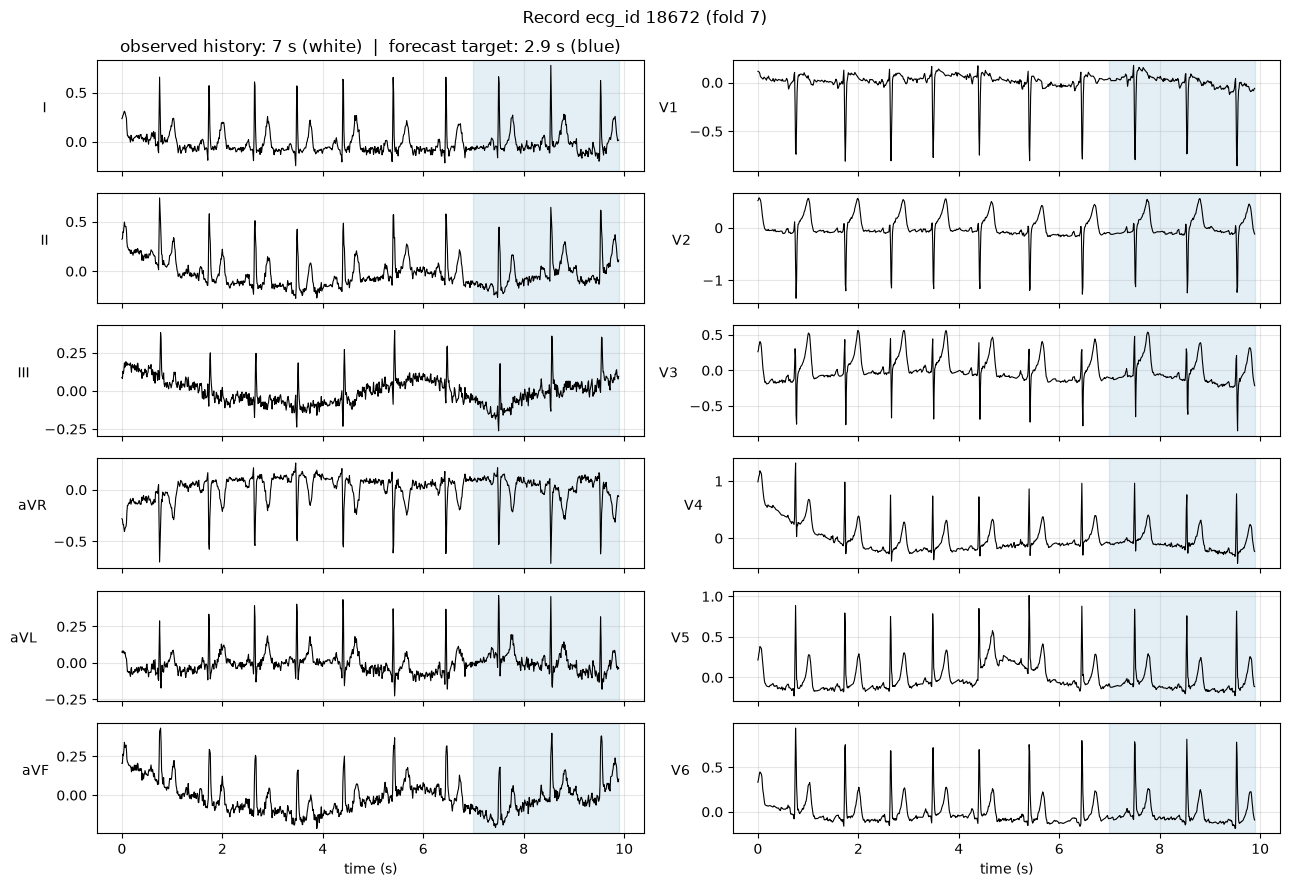

In [5]:
i = int(rng.integers(len(sig)))
t = np.arange(sig.shape[1]) / FS
fig, axes = plt.subplots(6, 2, figsize=(13, 9), sharex=True)
for lead, ax in zip(range(12), axes.T.ravel(), strict=True):
    ax.plot(t, sig[i, :, lead], lw=0.8, color="black")
    ax.axvspan(H / FS, (H + F) / FS, color="tab:blue", alpha=0.12)
    ax.set_ylabel(LEADS[lead], rotation=0, labelpad=15)
axes[0, 0].set_title("observed history: 7 s (white)  |  forecast target: 2.9 s (blue)")
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle(f"Record ecg_id {meta.index[i]} (fold {meta.strat_fold.iloc[i]})")
plt.tight_layout()
plt.show()

## 2. Leakage-free split (Phases 4 and 8)

- **Evaluation:** one official fold (patient-level, so no patient is in two folds).
- **Training pool:** the other dev folds, minus a **20% internal patient holdout** used only
  for early stopping (seed 0, as in the study).
- `train_fraction` takes a nested random subset of training *patients* (Phase 7 style).
- Fold 10 is never loaded: `load_dataset(..., "test")` raises `SealedFoldError` unless
  `data.allow_test=true` is set explicitly.

In [6]:
k = CONFIG["eval_fold"]
parts = patient_holdout(meta[meta.strat_fold != k], 0.2, seed=0)
pool = parts["train"]
patients = np.sort(pool.patient_id.unique())
order = np.random.default_rng(0).permutation(patients)
keep = set(order[: max(1, round(CONFIG["train_fraction"] * len(patients)))])
sub = pool[pool.patient_id.isin(keep)]

idx = meta.index.get_indexer
rows_train, rows_hold = idx(sub.index), idx(parts["val"].index)
rows_fold = np.flatnonzero(meta.strat_fold.to_numpy() == k)          # whole evaluation fold
n_eval = CONFIG["n_eval_records"] or len(rows_fold)
pos_eval = np.sort(rng.choice(len(rows_fold), min(n_eval, len(rows_fold)), replace=False))
rows_eval = rows_fold[pos_eval]                                     # scored subset

groups = {"train": rows_train, "holdout": rows_hold, "eval": rows_eval}
pids = {g: set(meta.patient_id.iloc[r]) for g, r in groups.items()}
assert not (pids["train"] & pids["holdout"]) and not (pids["train"] & pids["eval"]) \
    and not (pids["holdout"] & pids["eval"]), "patient leakage"
print(pd.DataFrame({g: {"records": len(r), "patients": len(pids[g])} for g, r in groups.items()}))
print("no patient appears in two groups ✓")

          train  holdout  eval
records    1379     3488   300
patients   1201     3001   298
no patient appears in two groups ✓


## 3. Reference forecasts (Phase 0)

| Name | How it is made | Uses the future? |
|---|---|---|
| **flat** | median of each lead's history, repeated | no |
| **`sn4`** | estimate the beat period from the history, average the last **4** cycles (level-matched to the last one), repeat forward | no |
| **oracle** | the history's beats placed at the **true** future R-peak times | **yes** – a diagnostic upper bound, not a forecaster |

`sn4` is read from the Phase 10 cache when available (identical values, checked in Phase 10);
otherwise it is computed here for the records that need it.

In [7]:
SN4_CACHE = Path(".cache/data/phase10/sn4_dev.npy")


def sn4_one(x):
    hist = x[:H].astype(np.float64)
    period, _ = p0.estimate_period(hist, p0.rpeaks(hist[:, 1]))
    return p0.seasonal(hist, period, F, p0.K_CYCLES)


needs_sn4 = CONFIG["train"] and CONFIG["model"] in ("gated", "additive", "input")
SN4 = np.full((len(sig), F, 12), np.nan, dtype=np.float32)
if SN4_CACHE.exists():
    SN4[:] = np.load(SN4_CACHE)
    print("sn4 loaded from", SN4_CACHE)
else:
    need = np.concatenate([rows_eval, rows_train, rows_hold]) if needs_sn4 else rows_eval
    t0 = time.time()
    for r in need:
        SN4[r] = sn4_one(sig[r])
    print(f"sn4 computed for {len(need):,} records in {time.time() - t0:.0f} s "
          "(cache it once with: uv run python research/phase10_objectives.py --stage sn4)")

x_eval = sig[rows_eval, :H].astype(np.float64)
y_eval = sig[rows_eval, H:H + F].astype(np.float64)
pid_eval = meta.patient_id.iloc[rows_eval].to_numpy()

PRED = {}   # method name -> (n_eval, 290, 12) forecast in mV
PRED["flat"] = np.repeat(np.median(x_eval, axis=1, keepdims=True), F, axis=1)
PRED["sn4"] = SN4[rows_eval].astype(np.float64)

oracle = []
for r in rows_eval:
    full = sig[r].astype(np.float64)
    o = p0.oracle_timing(full, p0.rpeaks(full[:, 1]), H, F, p0.K_CYCLES)
    oracle.append(PRED["sn4"][len(oracle)] if o is None else o)   # sn4 when no peaks found
PRED["oracle"] = np.stack(oracle)
print({m: p.shape for m, p in PRED.items()})

sn4 loaded from .cache/data/phase10/sn4_dev.npy


{'flat': (300, 290, 12), 'sn4': (300, 290, 12), 'oracle': (300, 290, 12)}


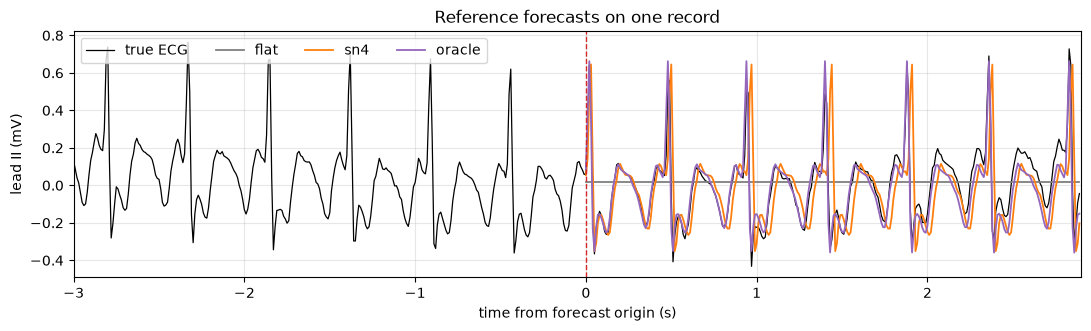

In [8]:
j = 0
tt = np.arange(-H, F) / FS
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(tt, sig[rows_eval[j], :H + F, 1], color="black", lw=0.9, label="true ECG")
for m in ("flat", "sn4", "oracle"):
    ax.plot(np.arange(F) / FS, PRED[m][j, :, 1], color=COLORS[m], lw=1.3, label=m)
ax.axvline(0, color="tab:red", ls="--", lw=1)
ax.set(xlim=(-3, F / FS), xlabel="time from forecast origin (s)", ylabel="lead II (mV)",
       title="Reference forecasts on one record")
ax.legend(ncol=4, loc="upper left")
plt.show()

## 4. Scoring: MAE plus three gatekeepers (Phase 6)

MAE alone rewards blur: a perfect ECG that is 50 ms late scores worse than a flat line.
So every forecast gets four scores (lower is better), each averaged **per patient first**:

| Metric | Measures |
|---|---|
| `mae` (primary) | pointwise error, mV |
| `dtw_mae` | shape error allowing ±100 ms shift, mV |
| `template_mae` | error of the median beat (morphology), mV |
| `beat_timing_ms` | distance between forecast and true R-peaks, ms |

**D6.2 rule:** A beats B only if A's ΔMAE 95% CI is entirely below 0 *and* no gatekeeper's
CI is entirely on the worse side.

In [9]:
t0 = time.time()
TRUE_PEAKS = [M.detect_beats(x_eval[i], y_eval[i]) for i in range(len(y_eval))]  # reused
SCORES = {}


def score(name):
    SCORES[name] = M.evaluate(x_eval, y_eval, PRED[name], true_peaks=TRUE_PEAKS)


def summary():
    rows = {m: {s: stats.patient_macro(df[s], pid_eval) for s in SUITE}
            for m, df in SCORES.items()}
    out = pd.DataFrame(rows).T
    out["≤50 ms (%)"] = [100 * stats.patient_macro(df.beat_timing_ms <= 50, pid_eval)
                         for df in SCORES.values()]
    return out.round({"mae": 4, "dtw_mae": 4, "template_mae": 4, "beat_timing_ms": 0,
                      "≤50 ms (%)": 0})


for m in ("flat", "sn4", "oracle"):
    score(m)
print(f"scored in {time.time() - t0:.0f} s")
summary()

scored in 4 s


,mae,dtw_mae,template_mae,beat_timing_ms,≤50 ms (%)
flat,0.1150,0.1150,0.1040,299.0,0.0
sn4,0.1193,0.0775,0.0588,83.0,46.0
oracle,0.0816,0.0644,0.0379,4.0,99.0


Things to notice (they are the starting point of the whole study):
- **flat beats `sn4` on MAE**, although `sn4` looks far more like an ECG.
- `sn4` is much better on the gatekeepers (template, timing).
- The **oracle** shows how much perfect timing would be worth (≈ 34% lower MAE in Phase 0):
  beat timing is the bottleneck.

## 5. Train your own model (Phases 9–11)

The pipeline turns each 7 s history into **24 channels** (a causal 0.67 Hz baseline +
residual per lead, D5.11); the target stays raw mV. Models using `sn4` get it as 12 extra
channels (`pack_baseline`).

The final model (`model="gated"`) is

$$\hat y = \sigma(\text{gate}(h)) \odot \text{sn4} + \text{correction}(h)$$

where $h$ is the CNN-LSTM's summary of the history: the network learns *how far to trust*
the repeated beats, per horizon step and lead.

Training: L1 loss, AdamW, early stopping on the internal holdout. Several seeds are averaged
(ensemble), as in the study.

In [10]:
USES_SN4 = CONFIG["model"] in ("gated", "additive", "input")


def build(name, in_ch):
    size = dict(width=CONFIG["width"], hidden=CONFIG["hidden"], layers=CONFIG["layers"])
    if name in ("gated", "additive"):
        return GatedBaselineCNNLSTM(in_ch, 12, F, additive=name == "additive", **size)
    if name == "input":
        return CNNLSTMForecaster(in_ch + 12, 12, F, **size)
    if name in MODELS:
        return MODELS[name](in_channels=in_ch, out_leads=12, horizon=F)
    raise ValueError(f"unknown model {name!r}")


MODEL_NAME = f"{CONFIG['model']} (yours)"
TRAINED, LOGS = [], []
if CONFIG["train"]:
    data = pack_baseline(sig, SN4, H) if USES_SN4 else sig
    seed_preds = []
    for s in CONFIG["seeds"]:
        p = cfg.preprocessing
        pipe = Pipeline(p.filter, p.scaler, False)
        pipe = BaselineConditioned(pipe) if USES_SN4 else pipe
        pipe.fit(data[rows_train, :H].astype(np.float64), sub.index)
        model = build(CONFIG["model"], pipe.in_channels)
        info = train_forecaster(model, pipe, data[rows_train], data[rows_hold], H, F, seed=s,
                                epochs=CONFIG["epochs"], patience=CONFIG["patience"],
                                lr=CONFIG["lr"], batch_size=CONFIG["batch"],
                                threads=CONFIG["threads"])
        n_par = sum(q.numel() for q in model.parameters())
        print(f"seed {s}: {info['epochs_run']} epochs, best epoch {info['best_epoch']}, "
              f"holdout L1 {info['best_holdout_l1']:.4f} mV, {n_par / 1e6:.2f} M params, "
              f"{info['seconds'] / 60:.1f} min")
        seed_preds.append(predict(model, pipe, data[rows_eval, :H].astype(np.float64)))
        TRAINED.append((model, pipe))
        LOGS.append(pd.DataFrame(info["log"]).assign(seed=s))
    PRED[MODEL_NAME] = np.mean(seed_preds, axis=0)   # seed ensemble
    score(MODEL_NAME)
else:
    print("training skipped (CONFIG['train'] = False)")

seed 42: 8 epochs, best epoch 8, holdout L1 0.0993 mV, 1.17 M params, 3.8 min


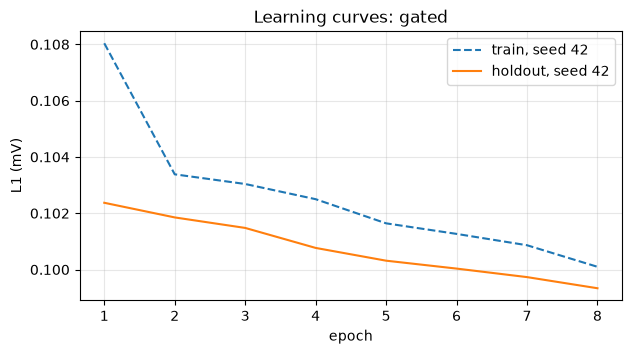

In [11]:
if LOGS:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for log in LOGS:
        ax.plot(log.epoch, log.train_l1, "--", label=f"train, seed {log.seed[0]}")
        ax.plot(log.epoch, log.holdout_l1, "-", label=f"holdout, seed {log.seed[0]}")
    ax.set(xlabel="epoch", ylabel="L1 (mV)", title=f"Learning curves: {CONFIG['model']}")
    ax.legend()
    plt.show()

## 6. The study's own results (cached runs)

If the study caches exist (`.cache/data/phase9`, `.cache/data/phase10`), this loads the
forecasts of models trained on the **full** training pool with 100 epochs, averaged over
their seeds (6 on fold 9, 3 on the other CV folds):

- **L1 CNN-LSTM** – the best Phase 9 architecture (plain L1 loss)
- **sn4-gated CNN-LSTM** – the final model (Phase 10, hidden 128)

These are out-of-fold forecasts: the evaluation fold was never used for training.

In [12]:
STUDY = {
    "L1 CNN-LSTM (study)": ".cache/data/phase9/cnn_lstm_lr0.001_12lead_k{k}_s{s}.npz",
    "sn4-gated CNN-LSTM (study)": ".cache/data/phase10/sn4_gated_lam0_k{k}_s{s}.npz",
}
if CONFIG["load_study_results"]:
    for name, pattern in STUDY.items():
        files = [Path(pattern.format(k=k, s=s)) for s in (42, 123, 999, 7, 2024, 31337)]
        files = [f for f in files if f.exists()]
        if not files:
            print(f"{name}: no cached runs for fold {k} – run the full pipeline (step 9)")
            continue
        preds = [np.load(f)["pred"] for f in files]
        assert preds[0].shape[0] == len(rows_fold), "cache does not match this dataset"
        PRED[name] = np.mean([p[pos_eval] for p in preds], axis=0).astype(np.float64)
        score(name)
        print(f"{name}: ensemble of {len(files)} seeds")
summary()

L1 CNN-LSTM (study): ensemble of 6 seeds


sn4-gated CNN-LSTM (study): ensemble of 6 seeds


,mae,dtw_mae,template_mae,beat_timing_ms,≤50 ms (%)
flat,0.1150,0.1150,0.1040,299.0,0.0
sn4,0.1193,0.0775,0.0588,83.0,46.0
oracle,0.0816,0.0644,0.0379,4.0,99.0
gated (yours),0.1020,0.0782,0.0781,88.0,43.0
L1 CNN-LSTM (study),0.0857,0.0750,0.1307,272.0,0.0
sn4-gated CNN-LSTM (study),0.0836,0.0665,0.0892,110.0,34.0


## 7. Compare methods

The bar charts show patient-macro scores; the table applies the **D6.2 rule** with a
paired patient bootstrap. (The study's decisions use `stats.compare_runs`, which also
resamples the 6 training runs per arm – Phase 8. Here each arm is one ensemble, so the
check is simplified.)

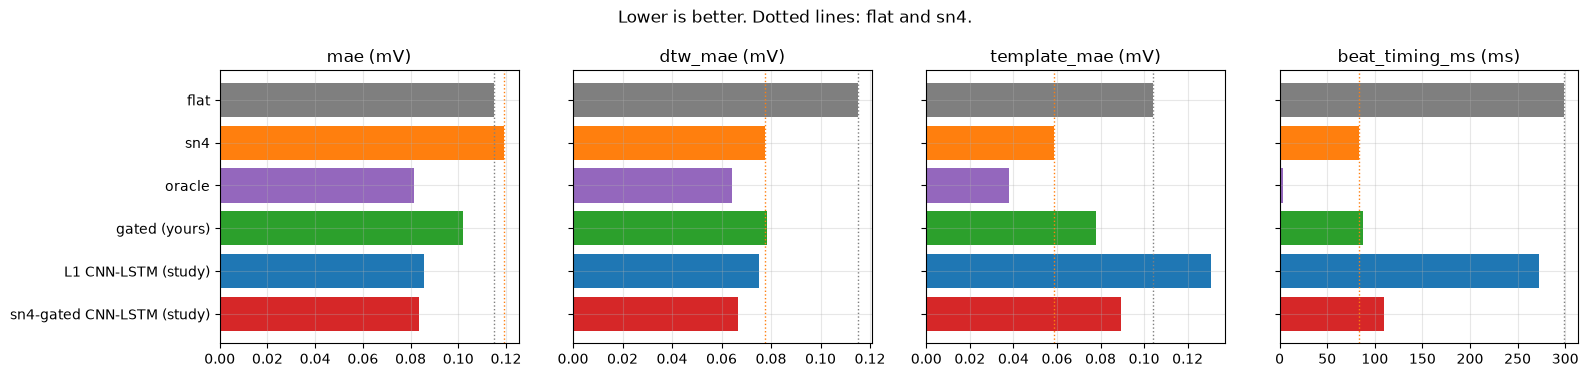

In [13]:
table = summary()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, m in zip(axes, SUITE, strict=True):
    vals = table[m]
    ax.barh(vals.index, vals.values, color=[color_of(n) for n in vals.index])
    ax.set_title(m + (" (ms)" if "ms" in m else " (mV)"))
    ax.invert_yaxis()
    for side in ("flat", "sn4"):
        ax.axvline(vals[side], color=COLORS[side], ls=":", lw=1)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("Lower is better. Dotted lines: flat and sn4.")
plt.tight_layout()
plt.show()

In [14]:
def d62(cand, ref):
    r = stats.compare(SCORES[cand], SCORES[ref], pid_eval, n_boot=1000)
    row = {f"Δ{m}": f"{r[m]['diff'] * (1 if 'ms' in m else 1000):+.1f} "
                    f"[{r[m]['lo'] * (1 if 'ms' in m else 1000):+.1f}, "
                    f"{r[m]['hi'] * (1 if 'ms' in m else 1000):+.1f}]" for m in SUITE}
    row["beats reference?"] = "✓" if r["beats_reference"] else "✗"
    return row


candidates = [m for m in PRED if m not in ("flat", "sn4", "oracle")]
rows = {(c, ref): d62(c, ref) for c in candidates for ref in ("flat", "sn4")}
if "L1 CNN-LSTM (study)" in PRED:
    rows.update({(c, "L1 CNN-LSTM (study)"): d62(c, "L1 CNN-LSTM (study)")
                 for c in candidates if c != "L1 CNN-LSTM (study)"})
cmp = pd.DataFrame(rows).T
cmp.index.names = ["candidate", "reference"]
print("Δ = candidate − reference: µV for mV metrics, ms for timing; [95% CI]. Negative = better.")
cmp

Δ = candidate − reference: µV for mV metrics, ms for timing; [95% CI]. Negative = better.


Δmae  \
candidate                  reference                                   
gated (yours)              flat                 -13.0 [-15.7, -10.3]   
                           sn4                  -17.4 [-20.6, -14.2]   
L1 CNN-LSTM (study)        flat                 -29.3 [-32.3, -26.3]   
                           sn4                  -33.6 [-38.6, -29.1]   
sn4-gated CNN-LSTM (study) flat                 -31.4 [-35.3, -27.7]   
                           sn4                  -35.7 [-39.6, -32.3]   
gated (yours)              L1 CNN-LSTM (study)  +16.3 [+14.1, +18.6]   
sn4-gated CNN-LSTM (study) L1 CNN-LSTM (study)     -2.1 [-4.2, -0.1]   

                                                            Δdtw_mae  \
candidate                  reference                                   
gated (yours)              flat                 -36.7 [-39.8, -33.7]   
                           sn4                     +0.7 [-2.5, +3.6]   
L1 CNN-LSTM (study)        flat                 -40.0 [-43.3, -36.9]   
                           sn4                     -2.5 [-7.2, +1.7]   
sn4-gated CNN-LSTM (study) flat                 -48.5 [-52.8, -44.3]   
                           sn4                   -11.0 [-14.8, -7.4]   
gated (yours)              L1 CNN-LSTM (study)     +3.3 [+1.2, +5.4]   
sn4-gated CNN-LSTM (study) L1 CNN-LSTM (study)    -8.5 [-10.7, -6.4]   

                                                       Δtemplate_mae  \
candidate                  reference                                   
gated (yours)              flat                 -25.9 [-28.2, -23.8]   
                           sn4                  +19.3 [+15.9, +22.6]   
L1 CNN-LSTM (study)        flat                 +26.6 [+23.0, +30.3]   
                           sn4                  +71.9 [+65.0, +78.5]   
sn4-gated CNN-LSTM (study) flat                 -14.9 [-19.1, -10.9]   
                           sn4                  +30.4 [+25.0, +35.5]   
gated (yours)              L1 CNN-LSTM (study)  -52.6 [-57.1, -47.8]   
sn4-gated CNN-LSTM (study) L1 CNN-LSTM (study)  -41.5 [-45.9, -37.1]   

                                                        Δbeat_timing_ms  \
candidate                  reference                                      
gated (yours)              flat                 -211.2 [-219.6, -201.6]   
                           sn4                        +4.8 [+1.8, +7.8]   
L1 CNN-LSTM (study)        flat                    -26.7 [-31.3, -22.2]   
                           sn4                  +189.4 [+179.1, +198.2]   
sn4-gated CNN-LSTM (study) flat                 -189.5 [-199.7, -178.3]   
                           sn4                     +26.6 [+20.6, +32.9]   
gated (yours)              L1 CNN-LSTM (study)  -184.5 [-193.8, -174.2]   
sn4-gated CNN-LSTM (study) L1 CNN-LSTM (study)  -162.8 [-174.0, -150.4]   

                                               beats reference?  
candidate                  reference                             
gated (yours)              flat                               ✓  
                           sn4                                ✗  
L1 CNN-LSTM (study)        flat                               ✗  
                           sn4                                ✗  
sn4-gated CNN-LSTM (study) flat                               ✓  
                           sn4                                ✗  
gated (yours)              L1 CNN-LSTM (study)                ✗  
sn4-gated CNN-LSTM (study) L1 CNN-LSTM (study)                ✓

## 8. Look at the forecasts (Phases 13–15)

Rows are example records, columns are leads. The red line is the forecast origin.

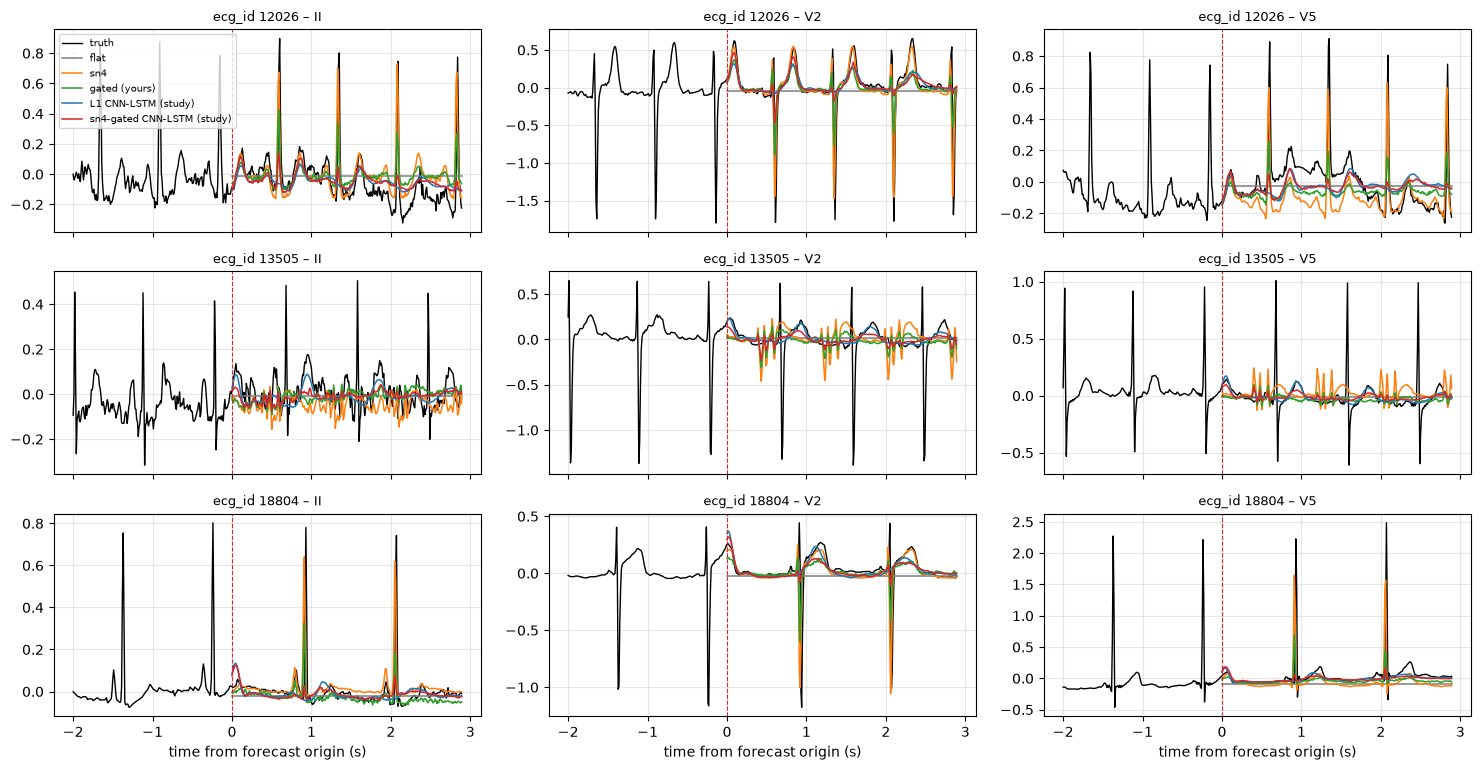

In [15]:
show = [m for m in PRED if m != "oracle"]
ex = np.sort(rng.choice(len(rows_eval), CONFIG["plot_records"], replace=False))
lead_ix = [LEADS.index(name) for name in CONFIG["plot_leads"]]
fig, axes = plt.subplots(len(ex), len(lead_ix), figsize=(5 * len(lead_ix), 2.6 * len(ex)),
                         squeeze=False, sharex=True)
for r, j in enumerate(ex):
    for c, li in enumerate(lead_ix):
        ax = axes[r, c]
        ax.plot(np.arange(-200, F) / FS, sig[rows_eval[j], H - 200:H + F, li], color="black",
                lw=1, label="truth")
        for m in show:
            ax.plot(np.arange(F) / FS, PRED[m][j, :, li], color=color_of(m), lw=1.1, label=m)
        ax.axvline(0, color="tab:red", ls="--", lw=0.8)
        ax.set_title(f"ecg_id {meta.index[rows_eval[j]]} – {LEADS[li]}", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("time from forecast origin (s)")
plt.tight_layout()
plt.show()

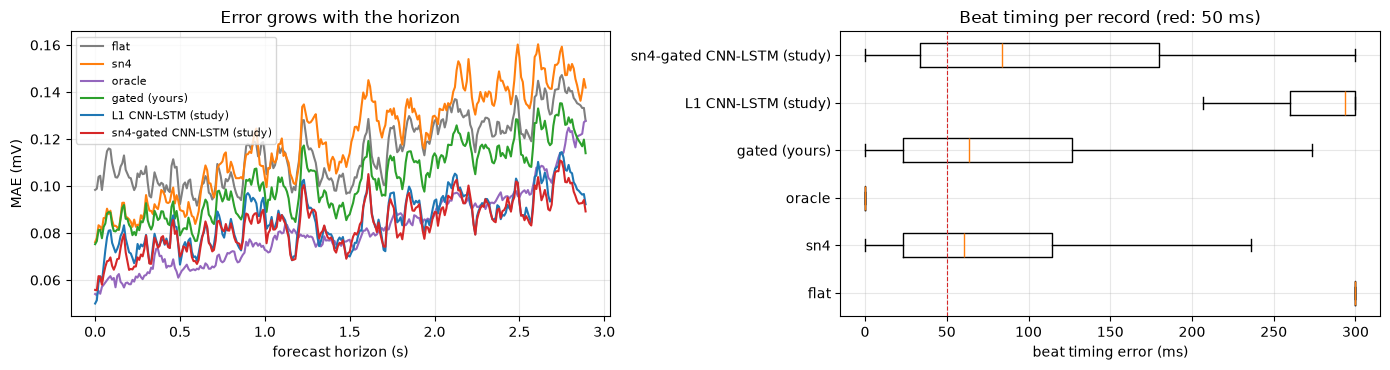

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for m in PRED:
    err = np.abs(PRED[m] - y_eval).mean(axis=2)                           # (records, steps)
    per_patient = pd.DataFrame(err).groupby(pid_eval).mean().mean()       # patient-macro
    ax[0].plot(np.arange(F) / FS, per_patient, color=color_of(m), label=m)
ax[0].set(xlabel="forecast horizon (s)", ylabel="MAE (mV)", title="Error grows with the horizon")
ax[0].legend(fontsize=8)
data_box = [SCORES[m].beat_timing_ms.dropna() for m in SCORES]
ax[1].boxplot(data_box, orientation="horizontal", showfliers=False)
ax[1].set_yticks(range(1, len(SCORES) + 1), list(SCORES))
ax[1].axvline(50, color="tab:red", ls="--", lw=0.8)
ax[1].set(xlabel="beat timing error (ms)", title="Beat timing per record (red: 50 ms)")
plt.tight_layout()
plt.show()

### The learned gate

The gate is the model's trust in `sn4`: near 1 the forecast follows the repeated beats,
near 0 it falls back to its own (smoother) correction. Phase 15 found that the gate tracks
how **periodic** the history is (Spearman ρ ≈ 0.47): it opens for regular rhythms and
closes for irregular ones such as AF/flutter.

Which model is shown (`CONFIG["gate_model"]`):
- **frozen final model** (Phase 16, seed 42) if it is cached. It was trained on folds 1–9,
  so the evaluation records may be in its training set: use it *only to look at the gate*,
  never to score.
- **your model** otherwise (needs `model="gated"`). After a short run the gate is still
  near its initial 0.5; train longer to see it learn.

Periodicity is the height of the history's autocorrelation peak at the beat period
(the same quantity `sn4` uses to find the cycle length).

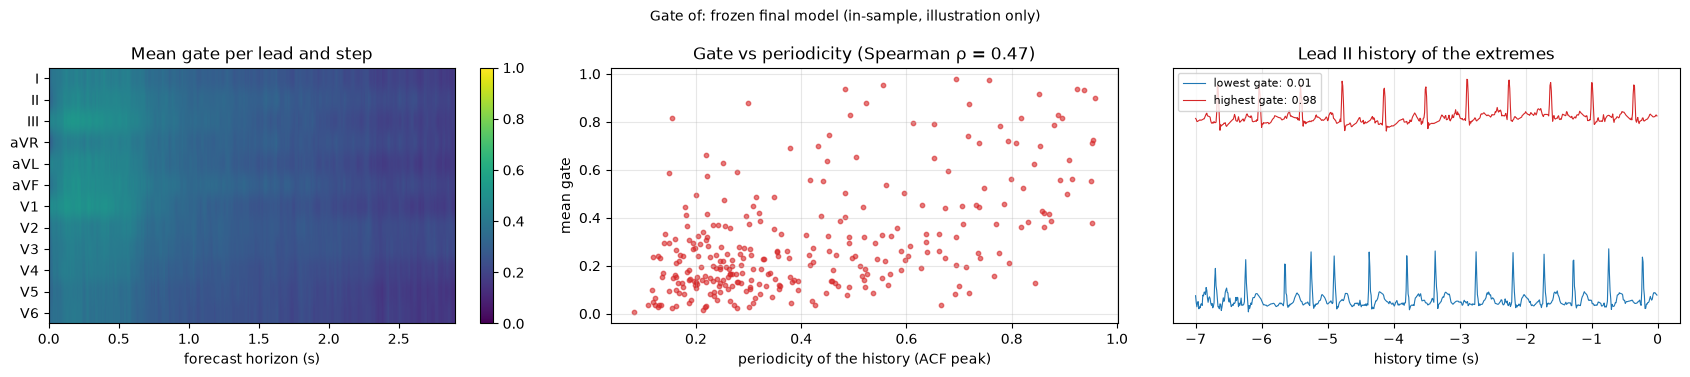

In [17]:
FROZEN = Path(".cache/data/phase16/final128_k10_s42")


def gate_values(model, pipe, rows):
    x = pack_baseline(sig[rows], SN4[rows], H)[:, :H].astype(np.float64)
    inp = torch.from_numpy(pipe.inputs(x).astype(np.float32))
    with torch.no_grad():
        hist = inp[..., : model.in_channels]
        z = model.body.stem(hist.transpose(1, 2)).transpose(1, 2)
        h = model.body.lstm(z)[0][:, -1]
        return torch.sigmoid(model.gate(h)).view(-1, F, 12).numpy()


gate_src = None
if CONFIG["gate_model"] == "auto" and FROZEN.with_suffix(".pt").exists():
    import pickle

    gpipe = pickle.load(FROZEN.with_suffix(".pipe.pkl").open("rb"))
    gmodel = GatedBaselineCNNLSTM(gpipe.in_channels, 12, F, 64, 128, 2)
    gmodel.load_state_dict(torch.load(FROZEN.with_suffix(".pt")))
    gate_src = "frozen final model (in-sample, illustration only)"
elif CONFIG["train"] and CONFIG["model"] == "gated":
    gmodel, gpipe = TRAINED[0]
    gate_src = MODEL_NAME

if gate_src is None:
    print("no gated model: set CONFIG['model'] = 'gated' (and train = True)")
else:
    g = gate_values(gmodel.eval(), gpipe, rows_eval)
    acf = np.array([p0.estimate_period(x, p0.rpeaks(x[:, 1]))[1] for x in x_eval])
    mean_gate = g.mean(axis=(1, 2))
    rho = pd.Series(mean_gate).corr(pd.Series(acf), method="spearman")

    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    im = ax[0].imshow(g.mean(0).T, aspect="auto", vmin=0, vmax=1, cmap="viridis",
                      extent=[0, F / FS, 11.5, -0.5])
    ax[0].set_yticks(range(12), LEADS)
    ax[0].grid(False)
    ax[0].set(xlabel="forecast horizon (s)", title="Mean gate per lead and step")
    fig.colorbar(im, ax=ax[0])
    ax[1].scatter(acf, mean_gate, s=10, alpha=0.6, color="tab:red")
    ax[1].set(xlabel="periodicity of the history (ACF peak)", ylabel="mean gate",
              title=f"Gate vs periodicity (Spearman ρ = {rho:.2f})")
    lo, hi = np.argmin(mean_gate), np.argmax(mean_gate)
    for j, label, c in ((lo, "lowest gate", "tab:blue"), (hi, "highest gate", "tab:red")):
        ax[2].plot(np.arange(-H, 0) / FS, x_eval[j, :, 1] + (0 if j == hi else -2), color=c,
                   lw=0.8, label=f"{label}: {mean_gate[j]:.2f}")
    ax[2].set(xlabel="history time (s)", yticks=[], title="Lead II history of the extremes")
    ax[2].legend(fontsize=8, loc="upper left")
    fig.suptitle(f"Gate of: {gate_src}", fontsize=10)
    plt.tight_layout()
    plt.show()

## 9. Running the full study

The notebook is a scaled-down replica. The reported numbers come from the research
scripts, which train on the full pool, use 6 seeds per arm, 100 epochs, 9-fold CV and the
`compare_runs` statistics. All runs are cached under `.cache/data`, so an interrupted
pipeline resumes where it stopped.

**Setup (once)**

```sh
uv sync --locked --extra cpu                       # or --extra cu126 / cu130 for NVIDIA
uv run python scripts/download_ptbxl.py --root PTB-XL
uv run pytest -q                                   # sanity check, ~1 min
```

**Compute budget (40-core CPU):** Phases 0–8 take a few hours; Phase 9 ≈ 18 h; Phase 10
≈ 9 h; Phases 11–18 another day. A GPU (`--extra cu126`) shortens training a lot.

The cell below lists every step in order. Set `RUN = True` and choose phases to execute
them from here (long!), or copy the commands into a terminal (recommended, e.g. inside
`tmux`).

In [18]:
PIPELINE = [
    ("0",   "Feasibility: flat, sn4, oracle",        "research/phase0_feasibility.py"),
    ("0",   "Feasibility figures",                   "research/phase0_figures.py"),
    ("1.5", "Data integrity (SHA-256)",               "research/phase1_5_verify_data.py"),
    ("2",   "Dataset analysis",                       "research/phase2_dataset.py"),
    ("3",   "Quality rules",                          "research/phase3_quality.py"),
    ("3",   "Cleaned dataset + trimming",             "research/phase3_cleaned_dataset.py"),
    ("4",   "Leakage audit",                          "research/phase4_leakage.py"),
    ("6",   "Evaluation metrics (before Phase 5)",    "research/phase6_metrics.py"),
    ("5",   "Preprocessing: signal level",            "research/phase5_signal_level.py"),
    ("5",   "Preprocessing: ridge variants",          "research/phase5_ridge.py"),
    ("5",   "Preprocessing: CNN augmentations",       "research/phase5_cnn.py --stage augment"),
    ("5",   "Preprocessing: CNN shortlist",           "research/phase5_cnn.py --stage shortlist"),
    ("5",   "Preprocessing figures",                  "research/phase5_figures.py"),
    ("5",   "Preprocessing replication",              "research/phase5_replication.py"),
    ("7",   "Data efficiency",                        "research/phase7_data_efficiency.py"),
    ("8",   "Validation protocol",                    "research/phase8_validation.py"),
    ("9",   "Models A: learning rate",                "research/phase9_models.py --stage A"),
    ("9",   "Models B: fold-9 screening",             "research/phase9_models.py --stage B"),
    ("9",   "Models C: 9-fold CV",                    "research/phase9_models.py --stage C"),
    ("9",   "Models D: 8-lead output",                "research/phase9_models.py --stage D"),
    ("9",   "Models report",                          "research/phase9_models.py --stage report"),
    ("10",  "Objectives: cache sn4",                  "research/phase10_objectives.py --stage sn4"),
    ("10",  "Objectives A: loss-weight pilot",        "research/phase10_objectives.py --stage A"),
    ("10",  "Objectives B: fold-9 screening",         "research/phase10_objectives.py --stage B"),
    ("10",  "Objectives C: 9-fold CV",                "research/phase10_objectives.py --stage C"),
    ("10",  "Objectives report",                      "research/phase10_objectives.py --stage report"),
    ("11",  "Tuning A: one change at a time",         "research/phase11_tuning.py --stage A"),
    ("11",  "Tuning B: fold-9 confirmation",          "research/phase11_tuning.py --stage B"),
    ("12-18", "Train + analyse 12, 13-15, 16, 18",    "research/run_12_18.py"),
    ("17",  "Test: code check on fold 9 (dry run)",   "research/phase17_test.py --dry-run"),
    # ("17", "Test: open fold 10 ONCE",              "research/phase17_test.py --unseal-fold-10-once"),
]
pd.DataFrame(PIPELINE, columns=["phase", "step", "command (uv run python ...)"])

,phase,step,command (uv run python ...)
0,0,"Feasibility: flat, sn4, oracle",research/phase0_feasibility.py
1,0,Feasibility figures,research/phase0_figures.py
2,1.5,Data integrity (SHA-256),research/phase1_5_verify_data.py
3,2,Dataset analysis,research/phase2_dataset.py
4,3,Quality rules,research/phase3_quality.py
5,3,Cleaned dataset + trimming,research/phase3_cleaned_dataset.py
6,4,Leakage audit,research/phase4_leakage.py
7,6,Evaluation metrics (before Phase 5),research/phase6_metrics.py
8,5,Preprocessing: signal level,research/phase5_signal_level.py
9,5,Preprocessing: ridge variants,research/phase5_ridge.py


In [19]:
import subprocess

RUN = False                 # set True to execute
PHASES = ["0", "1.5"]       # which phases to run, e.g. ["9"]; fold 10 stays commented out above

if RUN:
    for phase, step, cmd in PIPELINE:
        if phase not in PHASES:
            continue
        print(f"\n=== Phase {phase}: {step}\n$ uv run python {cmd}", flush=True)
        t0 = time.time()
        subprocess.run(["uv", "run", "--locked", "python", *cmd.split()], check=True)
        print(f"done in {(time.time() - t0) / 60:.1f} min")
else:
    print("RUN = False: nothing executed.")

RUN = False: nothing executed.


## Where to go next

- Try `model="cnn_lstm"` vs `model="gated"`: the gated model should improve template and
  timing errors at similar or lower MAE (Phase 10).
- Try `model="additive"` or `model="input"`: the Phase 18 ablations.
- Increase `train_fraction` to 1.0 and `epochs` to 100 (and `seeds` to six values) to
  approach the study's numbers – expect about 1 h per seed on 4 CPU threads.
- Read the matching phase report for each step: [`reports/STUDY_GUIDE.md`](../reports/STUDY_GUIDE.md).